<a href="https://colab.research.google.com/github/kirkuzn/PAD_KURS/blob/main/PAD_KURS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Выполнил: Кузнецов Кирилл, М26-555.
# 📊 Кейс: Анализ рынка авторитейла Казахстана и оценка эффективности «Меркур Авто»

## 🏢 Бизнес-контекст

Один из автоцентров холдинга — **«Меркур Авто»** — стремится определить свое текущее положение на рынке и выявить перспективные точки роста. Для реализации этой задачи были предоставлены операционные данные по всем продажам автомобилей в Казахстане за **9 месяцев 2019 года**.

> **Задача:** Подготовить данные и провести комплексный анализ, который позволит топ-менеджменту «Меркур Авто» объективно оценить операционную эффективность и принять обоснованные стратегические решения.

---

## ⚠️ Проблема
Исходные данные находятся в типичном для выгрузок из операционных систем (ERP/CRM) состоянии:
* ❌ Большое количество нестандартных форматов и типов данных.
* ❌ Наличие скрытых и неявных ошибок (дубликаты, пропуски, аномалии).
* ❌ Избыточная и нерелевантная информация.

*Без проведения тщательной предобработки и очистки данных качественный бизнес-анализ и построение корректных отчетов невозможны.*

---

## 🎯 Цели проекта

### 1. Техническая цель (Data Engineering)
* **Довести датасет** до эталонного состояния, пригодного для аналитики и построения моделей.
* **Разработать автоматизированный скрипт (Pipeline) очистки**, позволяющий быстро обрабатывать аналогичные массивы данных в будущем.

### 2. Аналитическая цель (BI & EDA)
* **Провести разведочный анализ (EDA)** всего автомобильного рынка Казахстана за указанный период.
* **Сформировать оценку рыночной позиции** автоцентра «Меркур Авто».
* **Рассчитать ключевые показатели эффективности (KPI)** дилерского центра и подготовить инсайты для менеджмента.


# 1. Загрузка и первичный осмотр данных.


In [122]:
# Импорт библиотек.
import gdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import files
from google.colab import output as colab_output

In [123]:
# Загрузка файла с репрезитория, чтение файла.
url = "https://raw.githubusercontent.com/kirkuzn/PAD_KURS/main/autokz2019.csv"
data = pd.read_csv(url, sep=';', decimal=',')

Просмотрим исходный датасет.

In [124]:
# Просмотр файла.
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39966 entries, 0 to 39965
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Год                             39966 non-null  int64  
 1   Месяц                           39966 non-null  object 
 2   Компания                        39966 non-null  object 
 3   Бренд                           39966 non-null  object 
 4   Модель                          39966 non-null  object 
 5   Модификация                     36375 non-null  object 
 6   Год выпуска                     39465 non-null  object 
 7   Страна-производитель            39966 non-null  object 
 8   Вид топлива                     36826 non-null  object 
 9   Объём двиг, л,                  35708 non-null  object 
 10  Коробка передач                 36711 non-null  object 
 11  Тип привода                     35677 non-null  object 
 12  Сегмент                         

Загружаем необходимые библиотеки. Загружаем файл. Проводим первичный осмотр. После первичного осмотра данных: файл состоит из **39 966** строк и **25** столбцов.

## Удаление столбцов, которые не несут аналитической ценности и содержат критичное количество пропусков.

In [125]:
# Делаем копию файла.
data_clean = data.copy()

# Удаляем столбцы.
drop_col = ['Наименование дилерского центра', 'Форма расчета', 'Сегмент',
            'Сегментация Eng', 'Локализация производства',
            'Тип клиента', 'Модификация']
data_clean = data_clean.drop(columns=drop_col)

# Переименовываем столбцы.
rename_col = {'Год': 'year', 'Месяц': 'month', 'Компания': 'company',
              'Бренд': 'brand', 'Модель': 'model',
              'Год выпуска': 'production_year',
              'Страна-производитель': 'country','Вид топлива': 'fuel_type',
              'Объём двиг, л,': 'engine_volume',
              'Коробка передач': 'transmission','Тип привода': 'drive_type',
              'Регион': 'region', 'Количество': 'quantity',
              'Цена, USD': 'price_usd',  'Продажа, USD': 'sales_usd',
              'Область': 'area', 'Сегментация 2013': 'segment_2013',
              'Класс 2013': 'class_2013'}
data_clean = data_clean.rename(columns=rename_col)

# Убираем лишние пробелы в столбцах.
for col in data_clean.select_dtypes(include='object').columns:
  data_clean[col] = data_clean[col].str.strip()

data_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39966 entries, 0 to 39965
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   year             39966 non-null  int64  
 1   month            39966 non-null  object 
 2   company          39966 non-null  object 
 3   brand            39966 non-null  object 
 4   model            39966 non-null  object 
 5   production_year  39465 non-null  object 
 6   country          39966 non-null  object 
 7   fuel_type        36826 non-null  object 
 8   engine_volume    35708 non-null  object 
 9   transmission     36711 non-null  object 
 10  drive_type       35677 non-null  object 
 11  region           39966 non-null  object 
 12  quantity         39960 non-null  float64
 13  price_usd        39966 non-null  float64
 14  sales_usd        39966 non-null  float64
 15  area             39966 non-null  object 
 16  segment_2013     39966 non-null  object 
 17  class_2013  

In [126]:
# Удаление полностью пустых строк.
print(f'Полностью пустых строк:', data_clean.isna().all(axis=1).sum())
data_clean = data_clean.dropna(how='all')

# Проверка явных дубликатов.
print(f'Найдено явных дубликатов:', data_clean.duplicated().sum())

Полностью пустых строк: 0
Найдено явных дубликатов: 23471


Вывявлены и удалены **7** столбцов, которые не несут аналитической ценности и содержат критичное количество пропусков. Переименованы на английский язык *18* столбцов. Полностью пустых строк не обнаружено. Выявлен *23471* дубликат. Столбцов до удаления: *25*, после: *18*.

In [127]:
# Проверка дубликатов.
dubs = data_clean[data_clean.duplicated(keep=False)].sort_values(by=['year',
                                                                    'month',
                                                                    'brand',
                                                                    'model'])

dubs[['year', 'month', 'company', 'brand', 'model', 'quantity', 'price_usd',
     'sales_usd']].head(10)

,year,month,company,brand,model,quantity,price_usd,sales_usd
39776,2019,Август,Allur Auto,ANKAI,HFF6850G,1.0,80294.40029,80294.40029
39777,2019,Август,Allur Auto,ANKAI,HFF6850G,1.0,80294.40029,80294.40029
39778,2019,Август,Allur Auto,ANKAI,HFF6850G,1.0,80294.40029,80294.40029
39779,2019,Август,Allur Auto,ANKAI,HFF6850G,1.0,80294.40029,80294.40029
39780,2019,Август,Allur Auto,ANKAI,HFF6850G,1.0,80294.40029,80294.40029
39526,2019,Август,Mercur Auto,Audi,Q8,1.0,78940.00000,78940.00000
39527,2019,Август,Mercur Auto,Audi,Q8,1.0,78940.00000,78940.00000
38829,2019,Август,Eurasia Motor Premium,Cadillac,Escalade,1.0,98485.86118,98485.86118
38830,2019,Август,Eurasia Motor Premium,Cadillac,Escalade,1.0,98485.86118,98485.86118
38834,2019,Август,Eurasia Motor Premium,Cadillac,Escalade,1.0,75349.61440,75349.61440


## Промежуточный итог осмотра данных.

На первом этапе был произведен импорт исходного файла `autokz2019.csv`. В ходе первичного осмотра (`data.info()`) было определено, что таблица состоит из **25 столбцов** и **39 966 строк**.

Часть столбцов не несла аналитической ценности, поэтому были удалены 7 неинформативных столбцов (Дилер, Форма расчета, Сегмент, Сегментация Eng, Локализация производства, Тип клиента, Модификация). Оставшиеся столбцы были переименованы на английский язык для удобства дальнейшей работы.

Далее была проведена проверка на дубликаты. Было найдено **23 471** повторяющаяся строка. Осмотр данных  показал, что это не технический сбой, а ** оптовые продажи** (когда компания покупала партию из 5 автомобилей, в систему это записывали как 5 отдельных строк).

Прямое удаление этих дубликатов привело бы к потере более 50% данных о рынке. Решение: не удалять их на данном этапе методом `drop_duplicates()`, а применить позже **группировку (`groupby`)**. Это позволит объединить одинаковые строки, сохранив точное суммарное количество проданных автомобилей и общую выручку.

# 2. Глубокая очистка и преобразование данных.


## Кодирование названия стран в стандартные трехбуквенные коды ALPHA-3.

In [128]:
# Просмотрим страны, и заменим их кодировкой в ручную.
print('Уникальные страны до кодировки:', data['Страна-производитель'].unique())
country_re = {'Российская Федерация': 'RUS', 'Республика Казахстан': 'KAZ',
              'Япония': 'JPN', 'Корея': 'KOR',
              'Германия': 'DEU', 'США': 'USA',
              'Австрия': 'AUT', 'Китай': 'CHN', 'Таиланд': 'THA',
              'Венгрия': 'HUN', 'Испания': 'ESP', 'Нидерланды': 'NLD',
              'Польша': 'POL', 'Белоруссия': 'BLR',
              'Бельгия': 'BEL', 'UK': 'GBR', 'Узбекистан': 'UZB',
              'Турция': 'TUR', 'Швеция': 'SWE'}
data_clean['country'] = data_clean['country'].replace(country_re)

# Просмотрим результат.
print('Уникальные страны после кодировки:', data_clean['country'].unique())

Уникальные страны до кодировки: ['Германия' 'США' 'Австрия' 'Республика Казахстан' 'Российская Федерация'
 'Корея' 'Япония' 'Таиланд' 'Китай' 'UK' 'Узбекистан' 'Венгрия' 'Турция'
 'Испания' 'Нидерланды' 'Польша' 'Швеция' 'Белоруссия' 'Бельгия']
Уникальные страны после кодировки: ['DEU' 'USA' 'AUT' 'KAZ' 'RUS' 'KOR' 'JPN' 'THA' 'CHN' 'GBR' 'UZB' 'HUN'
 'TUR' 'ESP' 'NLD' 'POL' 'SWE' 'BLR' 'BEL']


Успешная кодировка стран на Alpha-3: 'DEU' 'USA' 'AUT' 'KAZ' 'RUS' 'KOR' 'JPN' 'THA' 'CHN' 'GBR' 'UZB' 'HUN'
 'TUR' 'ESP' 'NLD' 'POL' 'SWE' 'BLR' 'BEL'.

##Кодирование вида топлива в краткие и понятные категории.

In [129]:
# Рассмотрим виды топлива, заменим так же вручную.
fuel_re = {'бензин': 'F', 'f': 'F',
           'дизель': 'D', 'd': 'D',
           'электро': 'E', 'электричество': 'E', 'e': 'E',
           'гибрид': 'HYB', 'hyb': 'HYB'}

# Приведем к единому стандарту.
data_clean['fuel_type'] = (
    data_clean['fuel_type'].str.strip().str.lower().map(fuel_re))

# Пропуски заменим на 'Не указано'.
data_clean['fuel_type'] = data_clean['fuel_type'].fillna('Не указано')

# Просмотрим результат.
print('Уникальные виды топлива:', data_clean['fuel_type'].unique())

Уникальные виды топлива: ['F' 'D' 'Не указано' 'HYB' 'E']


Успешное кодирование топлива на: 'F' 'D' 'Не указано' 'HYB' 'E'.

## Приведение типа привода к единому формату.

In [130]:
# Рассмотрим типы привода, заменим так же вручную.
drive_re = { 'Передний': 'FWD', 'передний': 'FWD', 'Передний (FF)': 'FWD',
            'FF': 'FWD', 'FWD': 'FWD','Задний': 'RWD', 'задний': 'RWD',
             'RWD': 'RWD', 'Полный': '4WD', 'полный': '4WD', 'AWD': '4WD',
             '4WD': '4WD', '4x4': '4WD', '4X4': '4WD', '4 WD': '4WD',
             '4Motion': '4WD', 'quattro': '4WD'}

# Пропуски заменим на 'Не указано'.
data_clean['drive_type'] = data_clean['drive_type'].str.strip().map(drive_re)
data_clean['drive_type'] = data_clean['drive_type'].fillna('Не указано')

# Просмотрим результат.
print('Уникальные типы привода:', data_clean['drive_type'].unique())

Уникальные типы привода: ['FWD' '4WD' 'RWD' 'Не указано']


Привеление типов привода к 'FWD' '4WD' 'RWD' 'Не указано'.

## Приведение столбцов: Стоимость, Количество и Итоговая стоимость - к корректным числовым типам.

In [131]:
# Приведение столбцов к числовому типу.
cols = ['quantity', 'price_usd', 'sales_usd']
data_clean[cols] = data_clean[cols].apply(pd.to_numeric, errors='coerce')

# Поиск возвратов и пропусков.
returns = (data_clean['quantity'] <= 0).sum()
nans = data_clean['quantity'].isna().sum()
print(f'Возвратов (<= 0): {returns}, пропусков (NaN): {nans}')

# Удаление некорректных записей.
before = len(data_clean)
data_clean = data_clean[data_clean['quantity'] > 0]
after = len(data_clean)
print(f'Строк: было {before} - стало {after} (удалено {before - after})')

# Просмотрим оптовые заказы.
print('Оптовые заказы:', data_clean['quantity'].max())
display(data_clean.nlargest(5, 'quantity')[['company', 'brand', 'model',
                                            'quantity', 'sales_usd']])

Возвратов (<= 0): 1, пропусков (NaN): 6
Строк: было 39966 - стало 39959 (удалено 7)
Оптовые заказы: 115.0


,company,brand,model,quantity,sales_usd
16885,БИПЭК АВТО,Lada,4x4,115.0,1035000.000
25555,БИПЭК АВТО,Skoda,Octavia,100.0,1870000.000
38408,Volkswagen Group Rus,Volkswagen,Polo,79.0,1261459.985
13699,Allur Auto,Jac,S3,70.0,1092976.745
16968,БИПЭК АВТО,Lada,4x4,66.0,594000.000


Удалено возвратов - 1, пропусков - 6. Строк: было 39966 - стало 39959.

## Создание единого столбца "Даты продажи".

In [132]:
# Сохраняем список столбцов до изменений.
cols_before = set(data_clean.columns)

# Заменяем названия месяцев на числа и собираем дату.
month_re = {'Январь': '01', 'Февраль': '02', 'Март': '03', 'Апрель': '04',
            'Май': '05', 'Июнь': '06', 'Июль': '07', 'Август': '08',
            'Сентябрь': '09', 'Октябрь': '10', 'Ноябрь': '11', 'Декабрь': '12'}
date_str = (data_clean['year'].astype(str) + '-' +
            data_clean['month'].map(month_re)+ '-01')
data_clean['sale_date'] = pd.to_datetime(date_str) + pd.offsets.MonthEnd(0)
data_clean = data_clean.drop(columns=['year', 'month'])

# Очищаем год выпуска от пробелов и переводим в Int64.
year = data_clean['production_year'].astype(str).str.replace(' ', '')
data_clean['production_year'] = pd.to_numeric(year,
                                              errors='coerce').astype('Int64')

# Проверяем изменения и результат.
cols_after = set(data_clean.columns)
print('Всего столбцов сейчас:', len(cols_after))
print('Удалили:', cols_before - cols_after)
print('Добавили:', cols_after - cols_before)
print('Месяцы продаж:', data_clean['sale_date'].nunique())
data_clean['production_year'].value_counts(dropna=False).sort_index()

Всего столбцов сейчас: 17
Удалили: {'year', 'month'}
Добавили: {'sale_date'}
Месяцы продаж: 9


,count
production_year,
2011,1
2013,1
2014,2
2016,30
2017,324
2018,8676
2019,29181
<NA>,1744


Содан столбец "sale_date'. Удалены исходные столбцы Год и Месяц. Столбцов стало: 17.


## Приведение названия дилерских центров к единому варианту.

In [133]:
# Просмотрим все компании до сортировки.
all_company_before = sorted(data_clean['company'].dropna().unique())
print(f'Количество компаний до единого варианта:', len(all_company_before))

# Заменим названия вручную.
company_re = {
    'Mercur Autos': 'Mercur Auto',
    'Autokapital': 'Автокапитал',
    'Caspian Motors': 'Каспиан Моторс',
    'MMC RUS': 'ММС Рус',
    'Ravon Motors Kazakstan': 'Равон Моторс Казахстан',
    'Hino Motors': 'Хино Моторс Казахстан'}

# Приведем к единому стандарту.
data_clean['company'] = data_clean['company'].str.strip().replace(company_re)

# Просмотрим все компании после сортировки.
all_company_after = sorted(data_clean['company'].dropna().unique())
print(f'Количество компаний после:', len(all_company_after))
all_company_after

Количество компаний до единого варианта: 39
Количество компаний после: 33


['Allur Auto',
 'Almaty Motors Premium',
 'Astana Motors',
 'Daewoo Bus Kazakhstan',
 'Eurasia Motor Premium',
 'Hyundai Com Trans Kazakhstan',
 'MAN Truck & Bus Kazakhstan',
 'Mercur Auto',
 'Nissan Manufacturing RUS',
 'Renault Россия',
 'Scandinavian Motors',
 'Scania Central Asia',
 'Subaru Kazakhstan',
 'TERRA MOTORS',
 'Toyota Motor Kazakhstan',
 'Volkswagen Group Rus',
 'Автодом Motors KST',
 'Автокапитал',
 'Автомир ГК',
 'Автомир-Центр',
 'Автоцентр-Бавария',
 'БИПЭК АВТО',
 'Вираж',
 'Каспиан Моторс',
 'Лифан Моторс Рус',
 'ММС Рус',
 'Равон Моторс Казахстан',
 'СВС-ТРАНС',
 'СемАЗ',
 'ТК КАМАЗ',
 'ТОО "Eurasia Motor Zhaik"',
 'УзАвто-Казахстан',
 'Хино Моторс Казахстан']

Количество компаний до единого варианта: 39
Количество компаний после: 33


## Приведение объёма двигателя.

In [134]:
# Приведем к единому стандарту.
engine = data_clean['engine_volume'].astype(str).str.replace(',', '.')
data_clean['engine_volume'] = engine.str.extract(r'(\d+\.?\d*)').astype(float)

# Исправим Chevrolet Niva.
niva = data_clean['model'].str.contains('Niva', case=False, na=False)
data_clean.loc[niva, 'engine_volume'] = 1.7

# Приведем к единому стандарту.
for col in data_clean.select_dtypes(include='object').columns:
    data_clean[col] = data_clean[col].str.strip()

# Исправим Volkswagen Polo.
polo_err = (data_clean['model'] == 'Polo') & (data_clean['engine_volume'] > 2.0)
data_clean.loc[polo_err, 'engine_volume'] = 1.6

# Заменим выбросы.
is_passenger = data_clean['segment_2013'] != 'Коммерческие автомобили'
bad_volume = data_clean['engine_volume'] > 10
bad_zero = (data_clean['engine_volume'] == 0) & (data_clean['fuel_type'] != 'E')
bad_engine = (is_passenger & bad_volume) | bad_zero
data_clean.loc[bad_engine, 'engine_volume'] = np.nan
data_clean.loc[data_clean['fuel_type'] == 'E', 'engine_volume'] = np.nan


# Просмотрим результат.
print('Макс. объем:', data_clean['engine_volume'].max())
print('Мин. объем:', data_clean['engine_volume'].min())
print('Пропуски:', data_clean['engine_volume'].isna().sum())

Макс. объем: 13.0
Мин. объем: 1.2
Пропуски: 4312


Макисмальный объем стал 13, минимальный 1.2. Пропусков до группировки - 4312.

## Приведение строки региона/области к нормальному регистру.

In [135]:
# Приведем к единому стандарту.
data_clean['region'] = data_clean['region'].str.strip().str.title()
data_clean['area'] = (data_clean['area'].str.strip().str.title()
                      .str.replace(r'^Г\.\s*', '', regex=True)
                      .replace({'Экспорт Область': 'Экспорт'}))

# Просмотрим результат.
print(data_clean['region'].dropna().unique().tolist())
print(data_clean['area'].dropna().unique().tolist())

['Алматы', 'Нур-Султан', 'Усть-Каменогорск', 'Уральск', 'Костанай', 'Павлодар', 'Семей', 'Шымкент', 'Актау', 'Атырау', 'Актобе', 'Караганда', 'Петропавловск', 'Кокшетау', 'Рудный', 'Кызылорда', 'Тараз', 'Туркестан', 'Талдыкорган', 'Экспорт', 'Кульсары', 'Каскелен', 'Экибастуз', 'Риддер', 'Сарыагаш', 'Зыряновск']
['Алматы', 'Нур-Султан', 'Восточно-Казахстанская Область', 'Западно-Казахстанская Область', 'Костанайская Область', 'Павлодарская Область', 'Южно-Казахстанская Область', 'Мангистауская Область', 'Атырауская Область', 'Актюбинская Область', 'Карагандинская Область', 'Северо-Казахстанская Область', 'Акмолинская Область', 'Кызылординская Область', 'Жамбылская Область', 'Туркестанская Область', 'Алматинская Область', 'Экспорт']


Добавлен регистр.

## Упрощение трансмисии до двух категорий (Автомат и Механика).

In [136]:
# Функция упрощения трансмисcии.
def transmission(text):
    if pd.isna(text):
        return 'Не указано'
    text = str(text).lower().strip()
    automat = ['amt', 'амт', 'at', 'ат', 'акп', 'cvt', 'вариатор', 'робот',
               'автомат', 'dsg', 'dct', 'tronic', 'pdk', 'shift', 'a/t', '4a',
               '4а', '5a', '5а', '6a', '6а', '7a', '7а', '8a', '8а', '9a',
               '9а', '12a', '12а' ]
    mechanika = ['mt', 'мт', 'мех', 'мкп', 'm/t', '5m', '6m', '5м', '6м']
    if any(word in text for word in automat):
        return 'Автомат'
    elif any(word in text for word in mechanika):
        return 'Механика'
    else:
        return 'Не указано'

# Просмотрим результат.
data_clean['transmission'] = data_clean['transmission'].apply(transmission)
print('Трансмиссии после очистки:', data_clean['transmission'].unique())

Трансмиссии после очистки: ['Автомат' 'Механика' 'Не указано']


Трансмиссии после очистки: 'Автомат' 'Механика' 'Не указано'.


## Заполнение пропусков, каскадная импутация для топлива и трансмиссии.

In [137]:
# Функция поиска самого частого значения.
def get_mode(s):
    m = s.dropna().mode()
    return next(iter(m), np.nan)

# Каскадная импутация для топлива, трансмиссии и привода.
total = data_clean['quantity'].sum()
levels = [['brand', 'model', 'production_year'],
          ['brand', 'model'], ['brand']]

for col in ['fuel_type', 'transmission', 'drive_type']:
# Было 'Не указано'.
    was = int(data_clean.loc[data_clean[col] == 'Не указано',
              'quantity'].sum())

# Заполняем 'Не указано'.
    s = data_clean[col].astype(str).replace('Не указано', np.nan)
    for keys in levels:
        s = s.fillna(data_clean.assign(_s=s)
                     .groupby(keys)['_s'].transform(get_mode))
    data_clean[col] = s.fillna('Не указано').astype('category')

# Стало 'Не указано'.
    became = int(data_clean.loc[data_clean[col] == 'Не указано',
                 'quantity'].sum())
    print(f'{col}: {was} ({was / total:.2%}) - {became} ({became / total:.2%})')

# Проверяем редкие типы топлива.
hyb = int(data_clean.loc[data_clean['fuel_type'] == 'HYB', 'quantity'].sum())
el = int(data_clean.loc[data_clean['fuel_type'] == 'E', 'quantity'].sum())
print(f'HYB: {hyb}, E: {el}')


fuel_type: 4425 (8.21%) - 668 (1.24%)
transmission: 4653 (8.64%) - 958 (1.78%)
drive_type: 15705 (29.15%) - 2491 (4.62%)
HYB: 10, E: 14


После каскадной импутации доля пропусков снизилась с 8,21% до 1,24% по типу топлива, с 8,64% до 1,78% по трансмиссии и с 29,15% до 4,62% по приводу, при этом редкие типы топлива (HYB — 10 шт., E — 14 шт.) успешно сохранились, а для уникальных моделей без аналогов оставлена категория 'Не указано'.


## Преобразования типов: столбец Дата продажи преобразован в тип datetime. Столбцы Тип топлива, Тип трансмиссии, Тип привода, Сегмент 2013, Класс 2013 преобразованы в категориальный тип category.

In [138]:
# Ошибки в сегментах и комплектациях.
data_clean.loc[data_clean['model'] == 'Master',
               'segment_2013'] = 'Коммерческие автомобили'
data_clean.loc[data_clean['model'] == 'Camaro', 'drive_type'] = 'RWD'

# Убираем скрытые пробелы по краям во всех строковых столбцах.
for col in data_clean.select_dtypes(include=['object', 'category']).columns:
    data_clean[col] = data_clean[col].astype(str).str.strip().replace('nan',
                                                                      np.nan)
data_clean['model'] = data_clean['model'].apply(lambda x: x[0].upper() + x[1:]
                                                if isinstance(x,
                                                              str) and x else x)

# Округляем цены и выручку до центов, переводим количество в целые числа.
data_clean['price_usd'] = data_clean['price_usd'].round(2)
data_clean['sales_usd'] = data_clean['sales_usd'].round(2)
data_clean['quantity'] = data_clean['quantity'].astype(int)

# Схлопываем одинаковые строки (оптовые заказы).
before = len(data_clean)
cols = list(data_clean.drop(columns=['quantity', 'sales_usd']).columns)
data_clean = data_clean.groupby(cols, as_index=False, dropna=False,
                                observed=True)[['quantity', 'sales_usd']].sum()
after = len(data_clean)
print(f'Строк: было {before} - стало {after} (схлопнуто {before - after})')

# Преобразование типов.
cat_cols = ['fuel_type', 'transmission', 'drive_type',
            'segment_2013', 'class_2013']
data_clean[cat_cols] = data_clean[cat_cols].astype('category')

# Просмотрим результат.
print('Размер:', data_clean.shape)
print('Авто:', data_clean['quantity'].sum())
print('Выручка:', round(data_clean['sales_usd'].sum(), 2))

Строк: было 39959 - стало 16070 (схлопнуто 23889)
Размер: (16070, 17)
Авто: 53875
Выручка: 1349194563.4


После исправления ошибок в сегментах, приведения типов и группировки повторяющихся записей таблица сократилась с 39 959 до 16 070 строки (17 столбцов), при этом суммарные показатели полностью сохранились (53 875 авто на сумму 1 349 194 563,4 USD).


In [139]:
# Просмотрим результат.
data_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16070 entries, 0 to 16069
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   company          16070 non-null  object        
 1   brand            16070 non-null  object        
 2   model            16070 non-null  object        
 3   production_year  15607 non-null  Int64         
 4   country          16070 non-null  object        
 5   fuel_type        16070 non-null  category      
 6   engine_volume    14674 non-null  float64       
 7   transmission     16070 non-null  category      
 8   drive_type       16070 non-null  category      
 9   region           16070 non-null  object        
 10  price_usd        16070 non-null  float64       
 11  area             16070 non-null  object        
 12  segment_2013     16070 non-null  category      
 13  class_2013       16070 non-null  category      
 14  sale_date        16070 non-null  datet

### Промежуточный итог очистки

* **Страна производства:** названия стран переведены в трехбуквенные коды ALPHA-3 (`KAZ`, `RUS`, `USA` и др.).
* **Вид топлива, трансмиссия и привод (каскадная импутация):** данные приведены к единым категориям (`F`, `D`, `E`, `HYB` для топлива; Автомат и Механика для трансмиссии; `FWD`, `RWD`, `4WD`, `2WD` для привода), или 'Не указано'. Для заполнения пропусков проведена каскадная импутация (поиск моды по 3 уровням: Бренд + Модель + Год → Бренд + Модель → Бренд). Это позволило снизить долю «Не указано» до **1.24%** в топливе, **1.78%** в трансмиссии и **4.62%** в приводе, сохранив информацию о редких авто (10 гибридах и 14 электромобилях).
* **Числовые столбцы и аномалии:** цены, количество и выручка переведены в числовой формат. Удалены **7 записей** с возвратами и нулевыми продажами (`quantity <= 0`). Было **39 966** — стало **39 959** строк. Крупные партии проверены — это оптовые заказы, поэтому они оставлены в таблице.
* **Дата продажи и год выпуска:** из года и месяца продажи создан столбец `sale_date` с последним днем месяца, старые столбцы удалены. В годе выпуска убраны скрытые пробелы, столбец переведен в формат `Int64`.
* **Название компании:** устранены неявные дубликаты и опечатки в названиях дилеров (в том числе `Mercur Autos` объединен с `Mercur Auto`). Было: **39**, стало: **33**.
* **Объем двигателя:** запятые заменены на точки. Выявлены и исправлены системные ошибки ввода: у электромобиля **Jaguar I-Pace** в объеме стояло «400 Л.С.» (перепутана мощность), а у электробуса **ANKAI** — емкость батареи (88.0). Для всех электромобилей объем двигателя заменен на `NaN` (так как у них нет ДВС). Аномалии **Chevrolet Niva** (21.7, 20.7 и т.д.) исправлены на реальные 1.7 л. Итоговый максимальный объем в базе — 13.0 л (для грузовиков), что соответствует реальности.
* **Регион и область:** названия приведены к нормальному регистру с заглавной буквы, а «Экспорт Область» заменено на «Экспорт».
* **Сегменты, комплектации и финал:** исправлены ошибки в данных (`Master` отнесен к коммерческим автомобилям, для `Camaro` установлен привод `RWD`). Дата продажи имеет тип `datetime`, 5 категориальных столбцов переведены в `category`. Повторяющиеся записи объединены через `groupby` с суммированием количества и выручки. Итоговая таблица: **17** столбцов, **16 070 строка**, **53 875 автомобилей** и **1 349 194 563.4 USD** выручки.


# 3. Исследовательский анализ данных (EDA).



## Анализ распределения основных показателей
Посмотрим, как распределены основные характеристики проданных авто, и построим три графика:
* **Гистограмму** для цены — чтобы увидеть самый популярный ценовой диапазон.
* **Гистограмму** для объема двигателя — чтобы понять, с каким объемом двигателя автомобиля покупают чаще.
* **Столбчатую диаграмму** для года выпуска — чтобы сравнить количество проданных машин по годам.


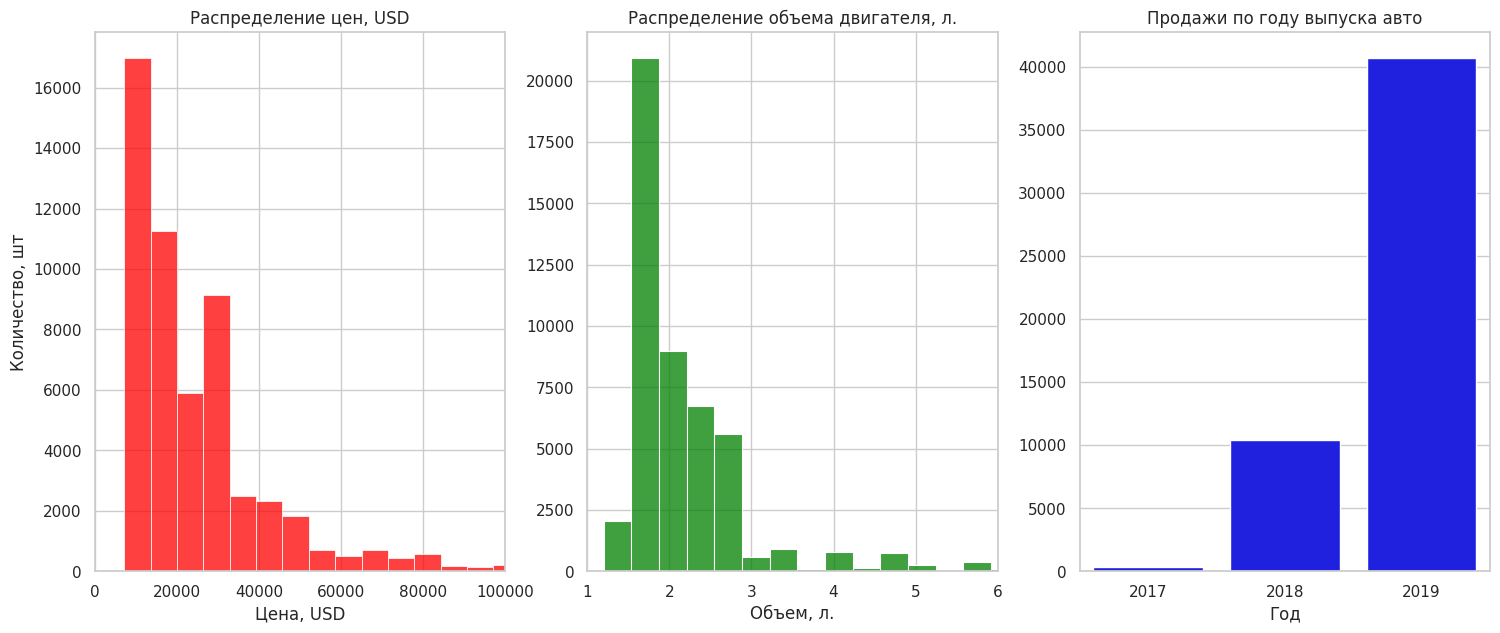

In [140]:
# Построение графика.
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# Распределение цен.
sns.histplot(data=data_clean, x='price_usd', weights='quantity', bins=50,
             ax=axes[0], color='red')
axes[0].set_xlim(0, 100000)
axes[0].set_title('Распределение цен, USD')
axes[0].set_xlabel('Цена, USD')
axes[0].set_ylabel('Количество, шт')

# Распределение объема двигателя.
sns.histplot(data=data_clean, x='engine_volume', weights='quantity', bins=35,
             ax=axes[1], color='green')
axes[1].set_xlim(1, 6)
axes[1].set_title('Распределение объема двигателя, л.')
axes[1].set_xlabel('Объем, л.')
axes[1].set_ylabel('')

# Распределение по количеству продаж в году.
year_sales = (data_clean[data_clean['production_year'] >= 2017]
              .groupby('production_year')['quantity'].sum())
sns.barplot(x=year_sales.index, y=year_sales.values, ax=axes[2], color='blue')
axes[2].set_title('Продажи по году выпуска авто')
axes[2].set_xlabel('Год')

# Просмотрим результат.
plt.show()

In [141]:
# Вывод статистики для непрерывных признаков.
st = data_clean.loc[data_clean.index.repeat(data_clean['quantity'])]
stats = st[['price_usd', 'engine_volume']].describe().loc[['mean', '25%',
                                                           '50%', '75%']]
display(stats.round({'price_usd': 0, 'engine_volume': 1}))

# Доли продаж по году выпуска.
years = (data_clean.groupby('production_year')['quantity']
         .sum().sort_index(ascending=False))
for year, count in years.items():
    print(f'{year}: {int(count)} шт. ({count / years.sum():.2%})')

,price_usd,engine_volume
mean,25043.0,2.2
25%,12300.0,1.6
50%,18857.0,2.0
75%,30618.0,2.5


2019: 40709 шт. (79.09%)
2018: 10387 шт. (20.18%)
2017: 340 шт. (0.66%)
2016: 30 шт. (0.06%)
2014: 2 шт. (0.00%)
2013: 1 шт. (0.00%)
2011: 1 шт. (0.00%)


### Вывод по графикам

* **Цена:** большинство машин продается в бюджетном и среднем сегменте — медианная цена составляет **18 857 USD** (основной диапазон 25%–75% от **12 300** до **30 618 USD**). Дорогие авто встречаются редко, но завышают среднюю цену до **25 043 USD**.
* **Объем двигателя:** самый популярный объем — от **1.6 до 2.5 л** (медиана — **2.0 л**). Машины с мощными двигателями (от 3.0 л) покупают редко.
* **Год выпуска:** почти **80%** всех продаж приходится на новые авто **2019 года** (**40 709** шт. или **79.09%**), заметно меньше — на **2018 год** (**10 387** шт. или **20.18%**), а доля машин **2017 года** и старше не превышает **1%** (**340** шт. или **0.66%** за 2017 год).


## Анализ продаж по городам и характеристикам авто

Cравним объемы продаж по разным категориям и построим три столбчатые диаграммы:
* **Горизонтальную столбчатую диаграмму** для топ-10 городов — чтобы увидеть регионы-лидеры по покупкам.
* **Столбчатую диаграмму** по виду топлива — чтобы понять, какие двигатели выбирают чаще (бензин, дизель и др.).
* **Столбчатую диаграмму** по типу трансмиссии — чтобы сравнить спрос на автомат и механику.


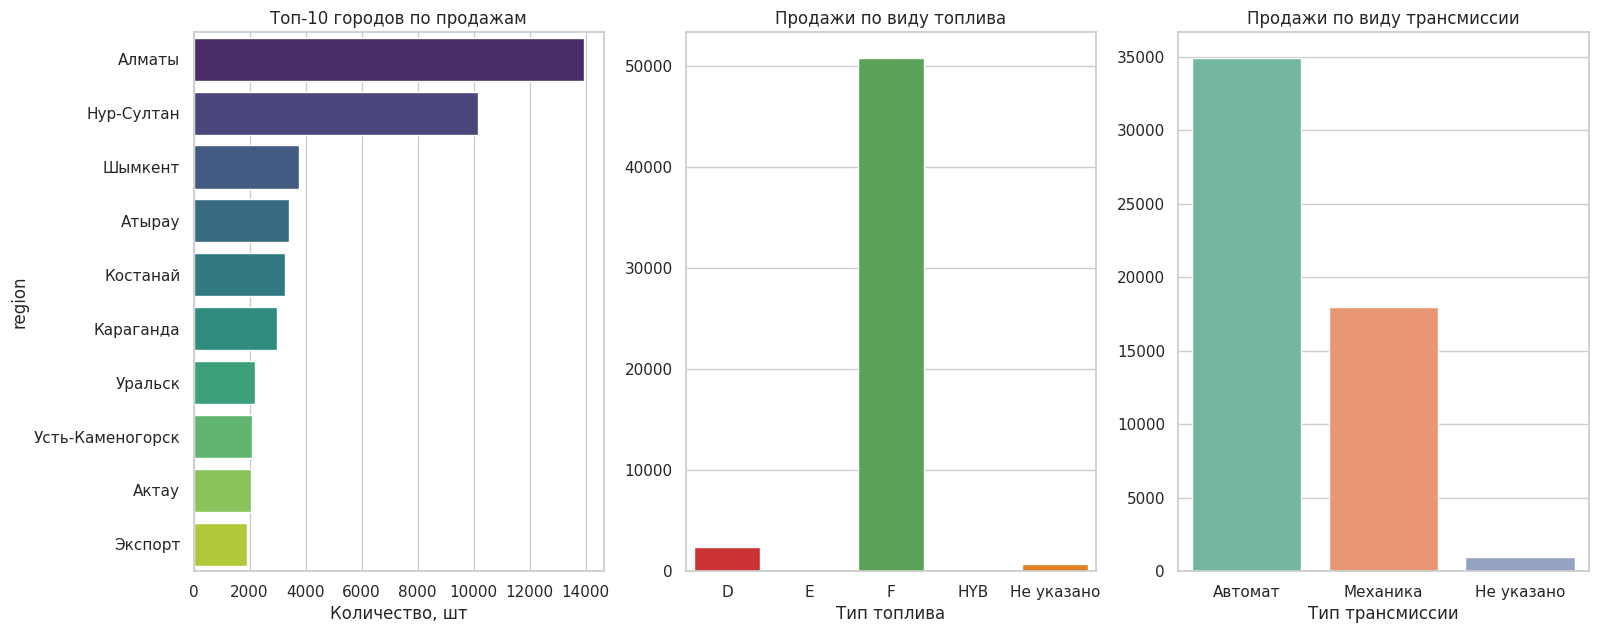

In [142]:
# Построение графика.
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# Топ-10 городов по продажам.
regions = (data_clean.groupby('region', observed=True)['quantity']
           .sum().sort_values(ascending=False).head(10))
sns.barplot(x=regions.values, y=regions.index, hue=regions.index,
            ax=axes[0], palette='viridis', legend=False)
axes[0].set_title('Топ-10 городов по продажам')
axes[0].set_xlabel('Количество, шт')

# Продажи по топливу.
fuel = (data_clean.groupby('fuel_type', observed=True)['quantity']
        .sum().sort_values(ascending=False))
sns.barplot(x=fuel.index, y=fuel.values, hue=fuel.index,
            ax=axes[1], palette='Set1', legend=False)
axes[1].set_title('Продажи по виду топлива')
axes[1].set_xlabel('Тип топлива')
axes[1].set_ylabel('')

# Продажи по трансмиссии.
trans = (data_clean.groupby('transmission', observed=True)['quantity']
         .sum().sort_values(ascending=False))
sns.barplot(x=trans.index, y=trans.values, hue=trans.index,
            ax=axes[2], palette='Set2', legend=False)
axes[2].set_title('Продажи по виду трансмиссии')
axes[2].set_xlabel('Тип трансмиссии')

# Просмотрим результат.
plt.show()

In [143]:
# Функция подсчета.
def get_stats(col, n=None):
    s = data_clean.groupby(col, observed=True)['quantity'].sum()
    s = s.sort_values(ascending=False)
    res = pd.DataFrame({'Количество': s.astype(int),
                        'Доля, %': (s / s.sum() * 100).round(2)})
    return res.head(n) if n else res

# Просмотрим результат.
print('Топ-3', get_stats('region', 3))
print()
print('Топливо', get_stats('fuel_type'))
print()
print('Трансмиссия', get_stats('transmission'))

Топ-3             Количество  Доля, %
region                         
Алматы           13947    25.89
Нур-Султан       10158    18.85
Шымкент           3749     6.96

Топливо             Количество  Доля, %
fuel_type                      
F                50772    94.24
D                 2411     4.48
Не указано         668     1.24
E                   14     0.03
HYB                 10     0.02

Трансмиссия               Количество  Доля, %
transmission                     
Автомат            34922    64.82
Механика           17995    33.40
Не указано           958     1.78


### Вывод по продажам по городам, топливу и трансмиссии

* **Города-лидеры:** больше половины всех продаж (51.7%) приходится на три крупнейших города: **Алматы** (13 947 шт. или 25.89%), **Нур-Султан** (10 158 шт. или 18.85%) и **Шымкент** (3 749 шт. или 6.96%).
* **Вид топлива:** абсолютное большинство покупателей выбирает бензиновые автомобили (`F`) — **50 772 шт. (94.24%)**. На дизель (`D`) приходится **2 411 шт. (4.48%)**, ещё **668 шт. (1.24%)** не указаны, а электромобили (`E`, 14 шт.) и гибриды (`HYB`, 10 шт.) занимают долю менее 0.1%.
* **Тип трансмиссии:** автомобили с автоматической коробкой передач заметно популярнее механики — их выбирают в **64.82%** случаев (34 922 шт.) против **33.40%** (17 995 шт.) у машин с механической коробкой (ещё в 1.78% случаев тип трансмиссии не указан).


## Анализ самых продаваемых брендов и моделей

Посмотрим, какие марки и конкретные автомобили пользуются наибольшим спросом у покупателей, и построим две горизонтальные столбчатые диаграммы:
* **Топ-10 брендов** — чтобы выделить главных лидеров авторынка по количеству проданных машин.
* **Топ-10 моделей** — чтобы определить самые популярные модели, которые делают основную кассу дилерам.


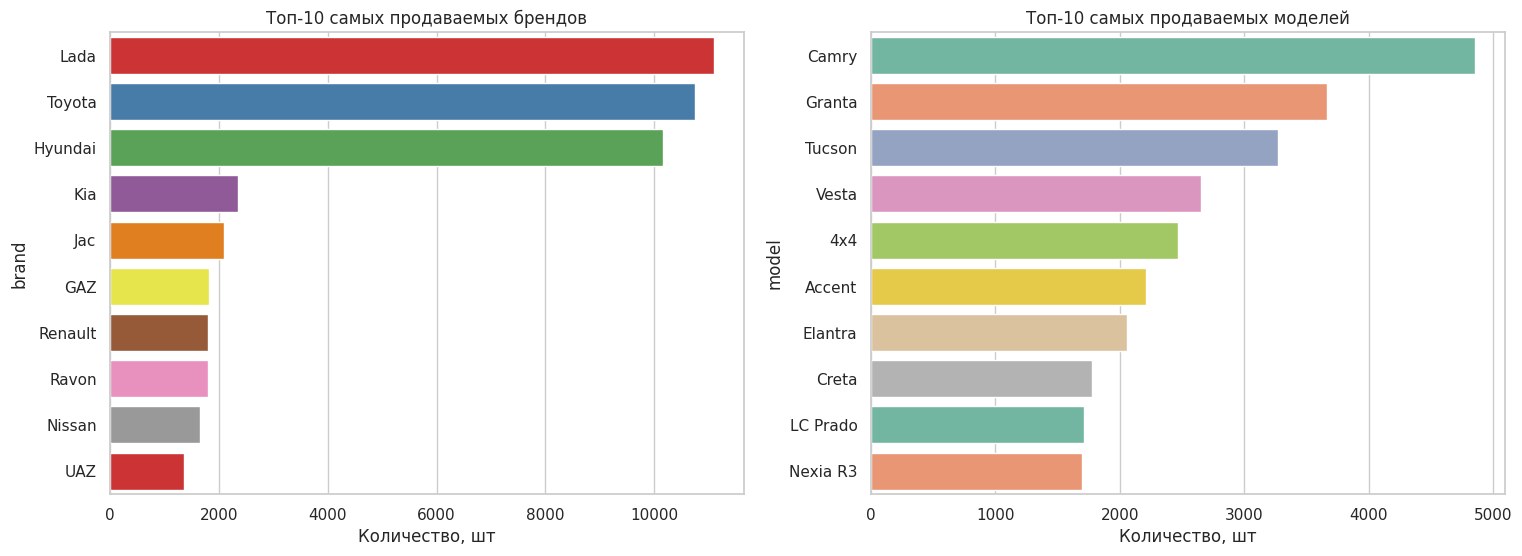

Топ-10 брендов:          Количество  Доля, %
brand                       
Lada          11092    20.59
Toyota        10745    19.94
Hyundai       10168    18.87
Kia            2358     4.38
Jac            2099     3.90
GAZ            1821     3.38
Renault        1796     3.33
Ravon          1795     3.33
Nissan         1664     3.09
UAZ            1361     2.53

Топ-10 моделей:           Количество  Доля, %
model                        
Camry           4853     9.01
Granta          3664     6.80
Tucson          3271     6.07
Vesta           2653     4.92
4x4             2469     4.58
Accent          2211     4.10
Elantra         2062     3.83
Creta           1775     3.29
LC Prado        1711     3.18
Nexia R3        1700     3.16


In [144]:
# Построение графика.
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Топ-10 брендов.
brands = (data_clean.groupby('brand', observed=True)['quantity']
          .sum().sort_values(ascending=False).head(10))
sns.barplot(x=brands.values, y=brands.index, hue=brands.index,
            ax=axes[0], palette='Set1', legend=False)
axes[0].set_title('Топ-10 самых продаваемых брендов')
axes[0].set_xlabel('Количество, шт')

# Топ-10 моделей.
models = (data_clean.groupby('model', observed=True)['quantity']
          .sum().sort_values(ascending=False).head(10))
sns.barplot(x=models.values, y=models.index, hue=models.index,
            ax=axes[1], palette='Set2', legend=False)
axes[1].set_title('Топ-10 самых продаваемых моделей')
axes[1].set_xlabel('Количество, шт')

# Просмотрим результат.
plt.show()

# Статистика.
print('Топ-10 брендов:', get_stats('brand', 10))
print()
print('Топ-10 моделей:', get_stats('model', 10))

### Вывод по брендам и моделям

* **Лидеры среди брендов:** почти **60%** всего рынка (59.40%) занимают три марки: **Lada** (11 092 шт. или **20.59%**), **Toyota** (10 745 шт. или **19.94%**) и **Hyundai** (10 168 шт. или **18.87%**). Ближайший преследователь — **Kia** — сильно отстает (2 358 шт. или **4.38%**).
* **Самые популярные модели:** абсолютным бестселлером является **Toyota Camry** — на неё приходится **9.01%** всех продаж (4 853 шт.). Далее идут массовые модели **Lada Granta** (3 664 шт. или **6.80%**), **Hyundai Tucson** (3 271 шт. или **6.07%**), **Lada Vesta** (2 653 шт. или **4.92%**) и **Lada 4x4** (2 469 шт. или **4.58%**).


## Анализ средней цены и выручки по брендам

Посмотрим на финансовые показатели марок и построим две горизонтальные столбчатые диаграммы:
* **Среднюю цену автомобиля по топ-10 брендам** — чтобы понять, в каком ценовом сегменте работают самые популярные марки.
* **Топ-10 брендов по объему выручки** — чтобы увидеть, какие бренды приносят рынку больше всего денег (с учетом не только количества машин, но и их стоимости).


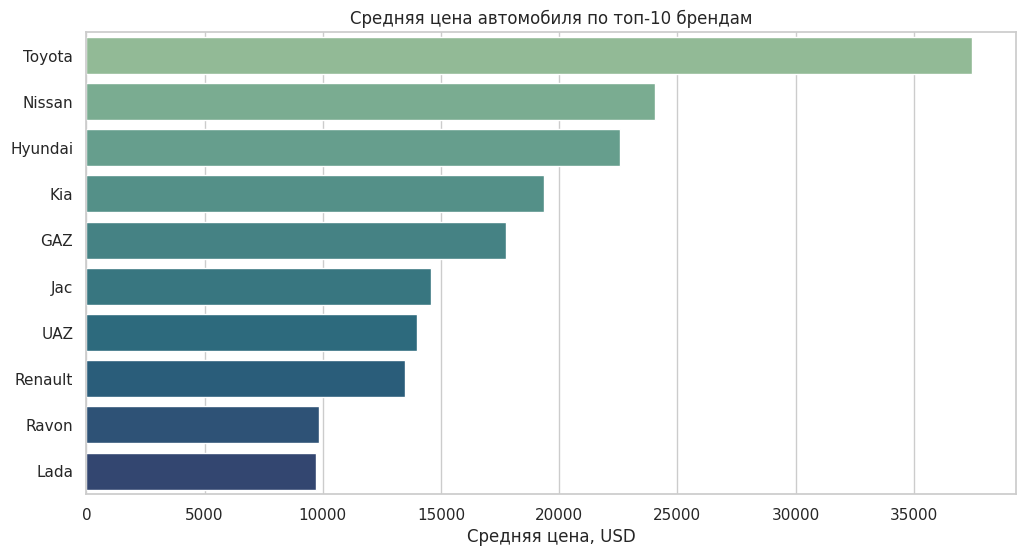

In [145]:
# Статистика.
top_10 = data_clean.groupby('brand')['quantity'].sum().nlargest(10).index
top = (data_clean[data_clean['brand'].isin(top_10)]
          .groupby('brand').sum(numeric_only=True))
avg_price = (top['sales_usd'] / top['quantity']).sort_values(ascending=False)

# Построение графика.
plt.figure(figsize=(12, 6))
sns.barplot(x=avg_price.values, y=avg_price.index, hue=avg_price.index,
            palette='crest', legend=False)
plt.title('Средняя цена автомобиля по топ-10 брендам')
plt.xlabel('Средняя цена, USD')
plt.ylabel('')

# Просмотрим результат.
plt.show()

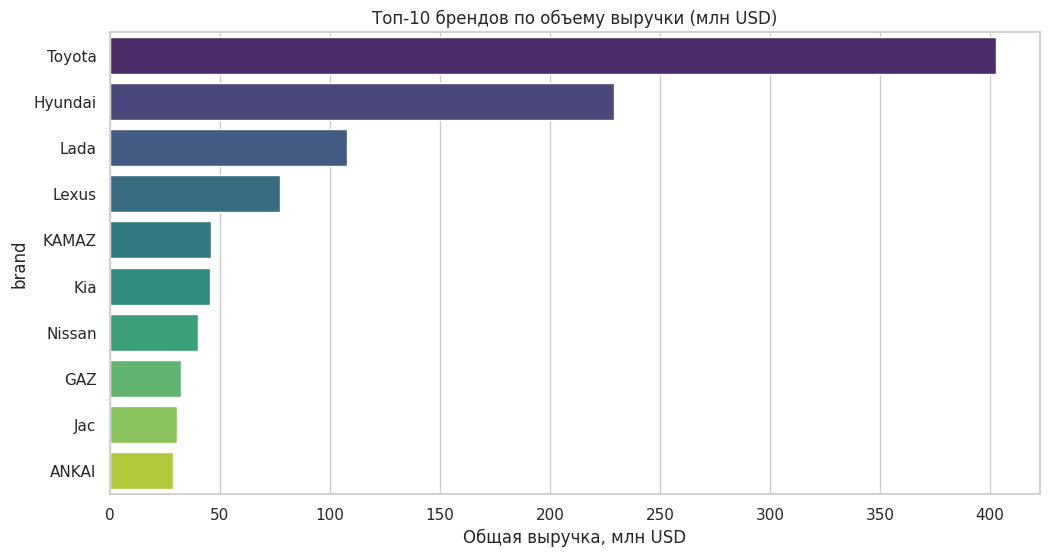

,Количество,Выручка_USD,"Доля_количества, %","Доля_выручки, %",Средняя_цена
brand,,,,,
Toyota,10745,402500073,19.94,29.83,37459
Hyundai,10168,229307594,18.87,17.00,22552
Lada,11092,107847478,20.59,7.99,9723
Lexus,1206,77376370,2.24,5.74,64160
KAMAZ,892,46092683,1.66,3.42,51673
Kia,2358,45669700,4.38,3.38,19368
Nissan,1664,40012772,3.09,2.97,24046
GAZ,1821,32286198,3.38,2.39,17730
Jac,2099,30589382,3.90,2.27,14573


In [146]:
# Топ-10 брендов по объему выручки.
top_rev = (data_clean.groupby('brand')['sales_usd']
           .sum().sort_values(ascending=False).head(10) / 1000000)

# Построение графика.
plt.figure(figsize=(12, 6))
sns.barplot(x=top_rev.values, y=top_rev.index, hue=top_rev.index,
            palette='viridis', legend=False)
plt.title('Топ-10 брендов по объему выручки (млн USD)')
plt.xlabel('Общая выручка, млн USD')

# Просмотрим результат.
plt.show()

# Вывод статистики
bs = (data_clean.groupby('brand', observed=True)
      .agg(Количество=('quantity', 'sum'), Выручка_USD=('sales_usd', 'sum'))
      .sort_values(by='Выручка_USD', ascending=False))

count = data_clean['quantity'].sum()
sales_sum = data_clean['sales_usd'].sum()

bs['Доля_количества, %'] = (bs['Количество'] / count * 100).round(2)
bs['Доля_выручки, %'] = (bs['Выручка_USD'] / sales_sum * 100).round(2)
bs['Средняя_цена'] = (bs['Выручка_USD'] / bs['Количество']).round(0)

# Выводим топ-10 по выручке (как на графике)
cols_int = {'Количество': int, 'Выручка_USD': int, 'Средняя_цена': int}
bs.head(10).astype(cols_int)

### Вывод по средней цене и выручке

* **Лидер по выручке:** несмотря на то что **Lada** занимает первое место по количеству проданных авто (11 092 шт.), главным лидером по деньгам является **Toyota** с выручкой **402.5 млн USD** (почти в 4 раза больше, чем у Lada — **107.8 млн USD**). На втором месте идет **Hyundai** (**229.3 млн USD**).
* **Разница в среднем чеке:** такой отрыв объясняется ценой автомобилей — средняя стоимость **Toyota** составляет **37 459 USD**, тогда как **Lada** является самой бюджетной маркой из топ-10 со средним чеком всего **9 723 USD**.
* **Влияние дорогих и коммерческих брендов:** в топ-10 по выручке попадают премиальные (**Lexus** — 4-е место) и коммерческие марки (**KAMAZ**, **ANKAI**), которые продаются небольшими партиями, но приносят крупную выручку за счет высокой цены за единицу.


### Корреляционный анализ числовых признаков

Проверим, как числовые характеристики (цена, объем двигателя, год выпуска и количество авто в сделке) связаны между собой, и построим **тепловую карту матрицы корреляций** — она наглядно покажет силу и направление зависимости между показателями.


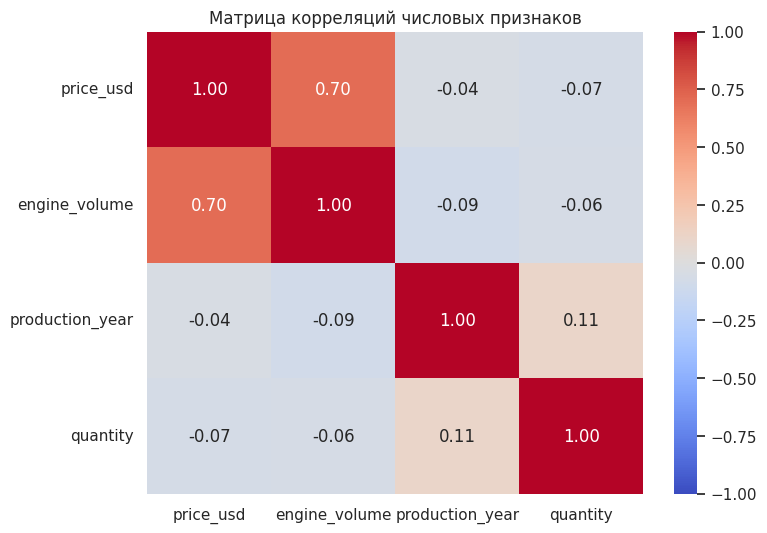

In [147]:
# Построение графика.
num_cols = ['price_usd', 'engine_volume', 'production_year', 'quantity']
corr_matrix = data_clean[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1,
            vmax=1)
plt.title('Матрица корреляций числовых признаков')

# Просмотрим результат.
plt.show()

### Вывод по матрице корреляций

* **Сильная связь цены и объема двигателя (`0.7`):** между стоимостью автомобиля и объемом мотора наблюдается заметная прямая зависимость — чем мощнее и объемнее двигатель, тем дороже машина.
* **Отсутствие связи с остальными параметрами:** год выпуска (`-0.06`) и количество автомобилей в заказе (`-0.07`) практически не влияют на цену. Это объясняется тем, что абсолютное большинство машин в выборке новые (2018–2019 гг.).

## Взаимосвязь объема двигателя и цены

Чтобы детальнее изучить выявленную корреляцию (`0.70`), построим **диаграмму рассеяния с линией тренда (`regplot`)** — она покажет, как именно растет цена автомобиля при увеличении объема двигателя и какой разброс цен существует внутри одного объема.


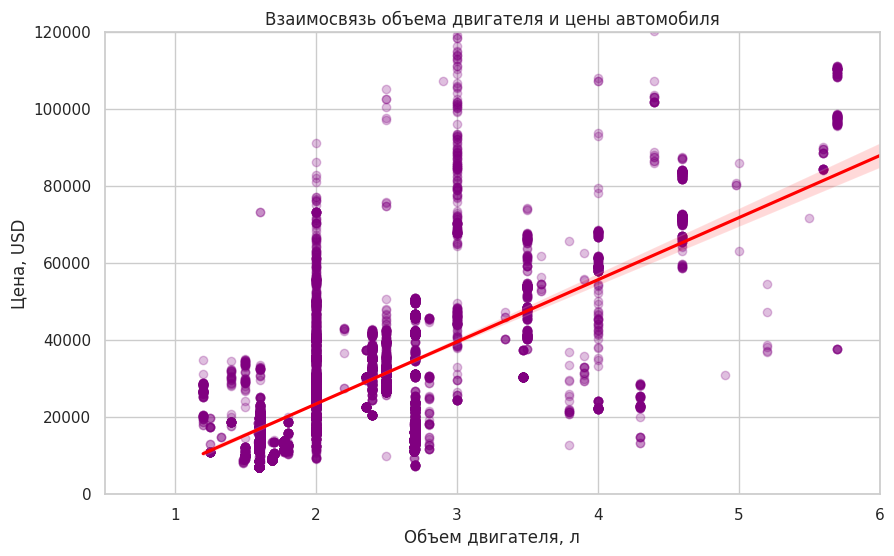

In [148]:
# Построение графика.
plt.figure(figsize=(10, 6))
sns.regplot(data=data_clean, x='engine_volume', y='price_usd',
            scatter_kws={'alpha': 0.25, 'color': 'purple'},
            line_kws={'color': 'red'})
plt.title('Взаимосвязь объема двигателя и цены автомобиля')
plt.xlabel('Объем двигателя, л')
plt.ylabel('Цена, USD')
plt.ylim(0, 120000)
plt.xlim(0.5, 6.0)

# Просмотрим результат.
plt.show()

### Вывод по графику взаимосвязи

* **Четкий восходящий тренд:** красная линия регрессии наглядно подтверждает прямую зависимость — с увеличением объема двигателя средняя стоимость автомобиля стабильно растет.
* **Высокий разброс цен внутри одного объема:** точки выстраиваются вертикальными полосами на популярных объемах (`1.6`, `2.0`, `2.5`, `3.0` л), при этом цена машин с одинаковым мотором может отличаться в несколько раз (например, при `2.0` л — от бюджетных **15 000 USD** до **75 000+ USD**). Значит, помимо объема двигателя на итоговую стоимость сильно влияют **бренд, класс автомобиля и комплектация**.


## Динамика продаж по месяцам

Посмотрим, как менялся спрос на автомобили в течение года, и построим **линейный график (`lineplot`)** — он наглядно покажет сезонные колебания, периоды спада и пиковые месяцы продаж с января по сентябрь 2019 года.


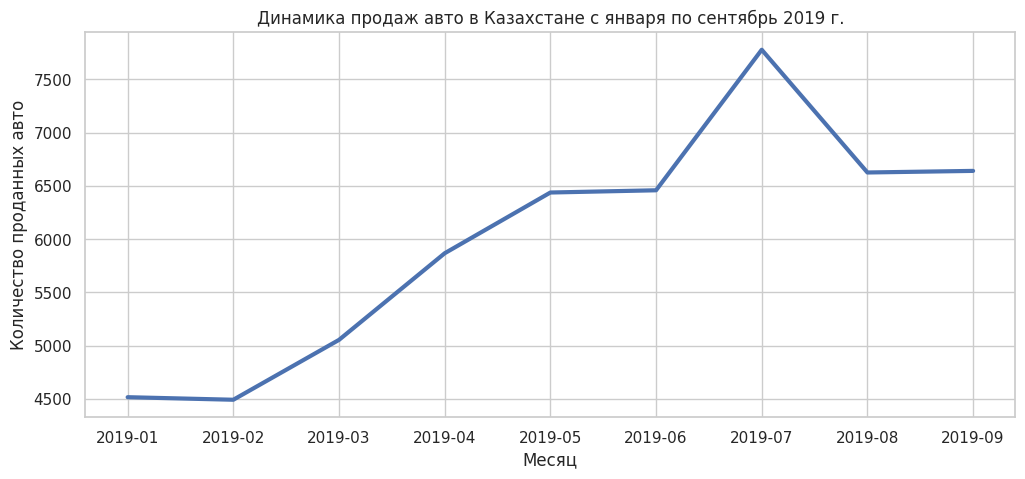

Месяц,Количество,"Доля, %","Прирост, %"
2019-01,4517,8.38,-
2019-02,4493,8.34,-0.53
2019-03,5055,9.38,+12.51
2019-04,5868,10.89,+16.08
2019-05,6438,11.95,+9.71
2019-06,6459,11.99,+0.33
2019-07,7778,14.44,+20.42
2019-08,6626,12.30,-14.81
2019-09,6641,12.33,+0.23


In [149]:
# Группировка данных.
monthly_sales = (data_clean.groupby("sale_date", observed=True)["quantity"]
                 .sum().reset_index())
monthly_sales["month_str"] = monthly_sales["sale_date"].dt.strftime("%Y-%m")

# Построение графика.
plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x='month_str', y='quantity', linewidth=3)
plt.title('Динамика продаж авто в Казахстане с января по сентябрь 2019 г.')
plt.xlabel('Месяц')
plt.ylabel('Количество проданных авто')

# Просмотрим результат.
plt.show()
stats = monthly_sales[['month_str', 'quantity']].copy()
stats['quantity'] = stats['quantity'].astype(int)
stats['Доля, %'] = (stats['quantity'] / stats['quantity'].sum() * 100).round(2)
stats['Прирост, %'] = (stats['quantity'].pct_change() * 100).round(2)
stats = stats.rename(columns={'month_str': 'Месяц', 'quantity': 'Количество'})
display(stats.style.hide(axis='index').format({'Доля, %': '{:.2f}',
                                               'Прирост, %': '{:+.2f}'},
                                               na_rep='-'))

### Вывод по динамике продаж

* Минимальные объемы продаж зафиксированы в начале года — в январе (**4 517** шт. или **8.38%**) и феврале (**4 493** шт. или **8.34%**). Начиная с марта спрос стабильно ускорялся (**+12.51%** в марте и **+16.08%** в апреле) и к маю–июню вышел на уровень около **6 450** машин в месяц (~**12%** доли рынка).
* **Июльский пик:** абсолютный рекорд продаж пришелся на **июль 2019 года** — **7 778** автомобилей (**14.44%** от всех продаж, резкий скачок на **+20.42%** к июню). В августе объем упал на **-14.81%** (до **6 626** шт.) и в сентябре возрос **6 641** шт. или **12.33%**.


### Выводы по разведочному анализу рынка (EDA)

* **Ценовой профиль и характеристики авто:** медианная цена проданного автомобиля составляет **18 857 USD** (основной диапазон 25%–75% — от **12 300** до **30 618 USD**), при этом средняя цена выше (**25 043 USD**). Разница между средней и медианой объясняется «длинным хвостом» дорогих внедорожников и люксовых моделей, которые тянут среднее вверх (поэтому в анализе опираемся на медиану). Медианный объём двигателя равен **2.0 л** (основной спрос в пределах **1.6–2.5 л**), а большинство машин выпущено в **2019** и **2018** годах.
* **География и технические предпочтения:** почти половина всех продаж (**44.74%**) приходится на **Алматы** (25.89%) и **Нур-Султан** (18.85%), третье место занимает **Шымкент** (6.96%). На рынке доминируют бензиновые двигатели (**94.24%**) и автоматическая трансмиссия (**64.82%**), тогда как электромобили (**0.03%**) и гибриды (**0.02%**) пока представлены единичными продажами.
* **Лидеры по объёму продаж (в штуках):** тройка лидеров контролирует почти **60% рынка** (59.40%) — **Lada** (20.59%), **Toyota** (19.94%) и **Hyundai** (18.87%). Среди конкретных моделей лидируют **Toyota Camry**, **Lada Granta**, **Hyundai Tucson**, **Lada Vesta** и **Lada 4x4**.
* **Лидеры по выручке (в деньгах):** безоговорочным лидером является **Toyota** (**402.5 млн USD**) за счет высокого среднего чека (**37 459 USD**). Далее идут **Hyundai** (**229.3 млн USD**) и **Lada** (**107.8 млн USD**). В топ-10 по выручке также входят премиальный **Lexus** и коммерческие бренды (**KAMAZ**, **ANKAI**).
* **Корреляционный анализ:** выявлена сильная прямая связь между ценой и объёмом двигателя (**r = 0.70**) — чем мощнее мотор, тем дороже автомобиль. При этом цена практически не зависит от года выпуска (**r = -0.06**) и размера партии (**r = -0.07**), так как основную массу выборки составляют новые авто, а крупные оптовые заказы чаще оформляются на бюджетные модели.
* **Динамика продаж по месяцам:** рынок демонстрирует выраженный весенне-летний рост с января по июль 2019 года — с **4 517** машин в январе (и **4 493** в феврале) до пиковых **7 778** авто в **июле** (**+20.42%** к июню). В августе и сентябре спрос скорректировался и стабилизировался на уровне около **6 600** машин в месяц (**6 626** и **6 641** шт.).


# 4. Анализ рынка и позиции «Меркур Авто»


## Сравнение ценового сегмента «Меркур Авто» и рынка

Начнем анализ позиций компании **«Меркур Авто»** со сравнения её ценовой политики с конкурентами. Для этого построим **диаграмму размаха («ящик с усами» / `boxplot`)** — она наглядно покажет медианную цену, основной ценовой диапазон (от 25-го до 75-го процентиля) и наличие дорогих моделей у компании по сравнению с остальным рынком.


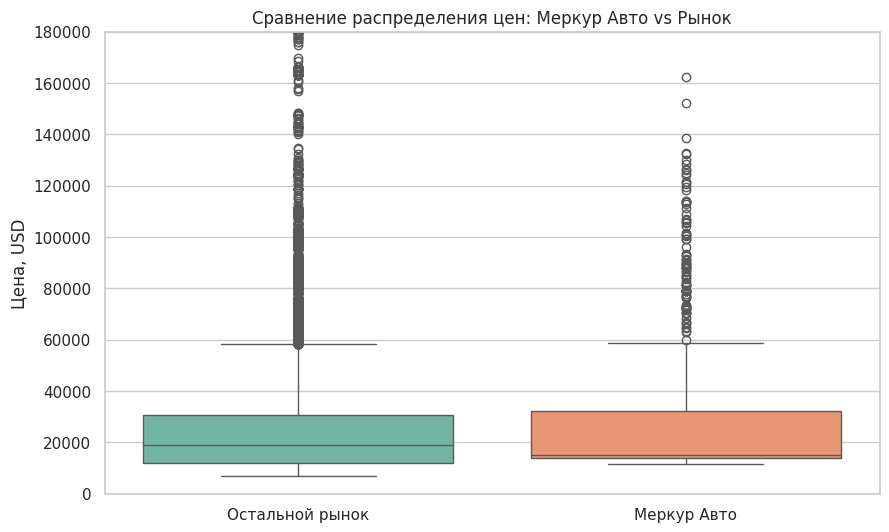

,count,mean,std,min,25%,50%,75%,max
Меркур Авто,650,29777,29382,11711,14132,15138,32096,193600
Остальной рынок,53225,24985,19713,7100,12194,18995,30618,328511


In [150]:
# Готовим данные с учетом количества авто.
idx = data_clean.index.repeat(data_clean["quantity"])
prices = data_clean.loc[idx, "price_usd"]
groups = np.where(data_clean.loc[idx, "company"] == "Mercur Auto",
                  "Меркур Авто", "Остальной рынок")

# Построение графика.
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x=groups, y=prices, hue=groups, ax=ax, palette="Set2", legend=False)

ax.set_ylim(0, 180000)
ax.set_title("Сравнение распределения цен: Меркур Авто vs Рынок")
ax.set_xlabel("")
ax.set_ylabel("Цена, USD")
plt.show()

# Статистика.
display(prices.groupby(groups).describe().round(0).astype(int))

### Вывод по сравнению цен

* **Близкий основной диапазон:** границы «ящиков» (от 25% до 75% продаж) у **Mercur Auto** и остального рынка почти совпадают — от **14 132** до **32 096 USD** против **12 194** – **30 618 USD** по рынку. При этом медианная цена у компании ниже рыночной (**15 138 USD** против **18 995 USD**).
* **Присутствие в премиум-сегменте:** верхний «ус» (около **59 000 USD**) и плотный ряд выбросов выше этой отметки (до **193 600 USD**) говорят о том, что компания, как и рынок в целом, активно работает не только в массовом сегменте, но и продаёт дорогие внедорожники и люксовые автомобили.


## Детальное сравнение распределения цен (KDE-график)

Чтобы подробнее рассмотреть структуру цен и не терять наглядность из-за длинного «хвоста» дорогих машин, построим **график ядерной оценки плотности (`kdeplot`) в логарифмической шкале** — он покажет, в каких именно ценовых зонах сосредоточены основные объемы продаж «Меркур Авто» и остального рынка.


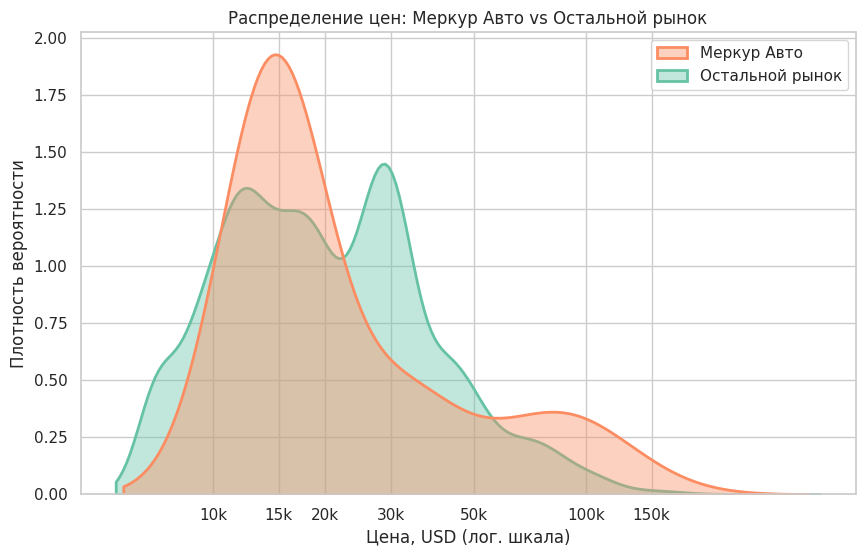

price_usd,До 20k (бюджет),20k–45k (средний),Свыше 45k (премиум)
row_0,,,
Меркур Авто,68.15,15.23,16.62
Остальной рынок,52.36,36.81,10.84


In [151]:
# Построение графика.
fig, ax = plt.subplots(figsize=(10, 6))

# Плотность распределения цен.
groups_plot = np.where(data_clean["company"] == "Mercur Auto",
                       "Меркур Авто", "Остальной рынок")

sns.kdeplot(data=data_clean, x="price_usd", weights="quantity", hue=groups_plot,
            hue_order=["Меркур Авто", "Остальной рынок"],
            palette=["#fc8d62", "#66c2a5"], common_norm=False,
            fill=True, alpha=0.4, linewidth=2, log_scale=True, ax=ax)

ticks = [10000, 15000, 20000, 30000, 50000, 100000, 150000]
labels = ["10k", "15k", "20k", "30k", "50k", "100k", "150k"]
ax.set_xticks(ticks, labels)
ax.minorticks_off()
ax.set_title("Распределение цен: Меркур Авто vs Остальной рынок")
ax.set_xlabel("Цена, USD (лог. шкала)")
ax.set_ylabel("Плотность вероятности")
plt.show()

# Доли продаж по ценовым сегментам (%).
bins = [0, 20000, 45000, float("inf")]
seg_labels = ["До 20k (бюджет)", "20k–45k (средний)", "Свыше 45k (премиум)"]
segments = pd.cut(prices, bins=bins, labels=seg_labels)

display(pd.crosstab(groups, segments, normalize="index").mul(100).round(2))

### Вывод по плотности распределения цен

* **Основной упор на бюджетные авто:** больше двух третей всех продаж **Mercur Auto** (**68.15%**) приходится на доступные машины до 20 000 USD (по остальному рынку таких **52.36%**). Поэтому на графике у компании выраженный пик в районе 15k, а медианная цена заметно ниже рыночной — **15 138 USD** против **18 995 USD**.
* **Провал в среднем сегменте и перевес в премиуме:** в среднем классе (20 000–45 000 USD) доля **Mercur Auto** более чем вдвое меньше, чем у конкурентов — всего **15.23%** против **36.81%** (у рынка здесь виден второй крупный пик около 30k). Зато в премиум-сегменте (дороже 45 000 USD) компания обгоняет рынок (**16.62%** против **10.84%**), за счёт чего её средняя цена (**29 777 USD**) оказывается выше средней по рынку (**24 985 USD**).


## Структура продаж по ценовым сегментам

Чтобы наглядно сравнить доли разных ценовых категорий у **«Меркур Авто»** и конкурентов, разделим все автомобили на четыре сегмента — **Бюджет** (до 15k USD), **Средний** (15k–30k USD), **Бизнес** (30k–60k USD) и **Премиум** (свыше 60k USD) — и построим **сгруппированную столбчатую диаграмму (`barplot`)**.


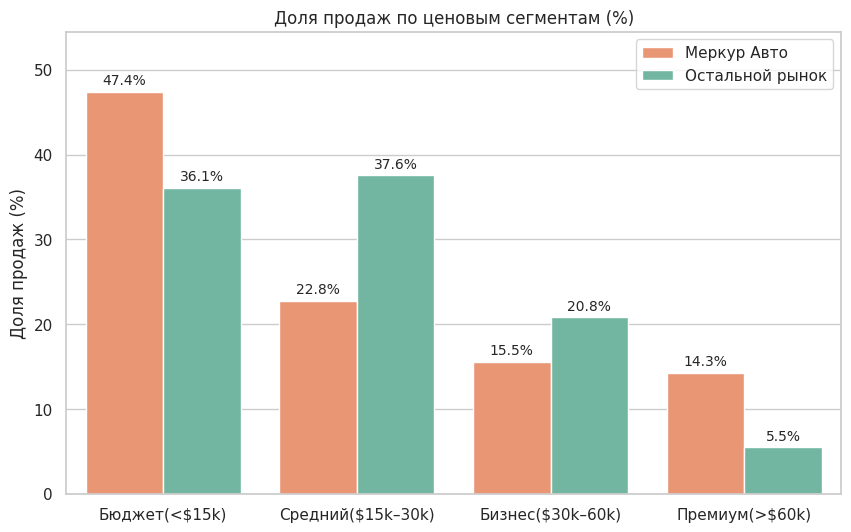

In [152]:
# Построение графика.
fig, ax = plt.subplots(figsize=(10, 6))

# Подготовка долей продаж по ценовым сегментам.
bins = [0, 15000, 30000, 60000, float('inf')]
labels = ['Бюджет(<$15k)', 'Средний($15k–30k)',
          'Бизнес($30k–60k)', 'Премиум(>$60k)']

groups = np.where(data_clean['company'] == 'Mercur Auto',
                  'Меркур Авто', 'Остальной рынок')
segments = pd.cut(data_clean['price_usd'], bins=bins, labels=labels)

seg_counts = data_clean.groupby(
    [groups, segments], observed=True)['quantity'].sum().reset_index()
seg_counts.columns = ['is_mercur', 'price_segment', 'quantity']
totals = seg_counts.groupby('is_mercur')['quantity'].transform('sum')
seg_counts['share'] = seg_counts['quantity'] / totals * 100

# Отрисовка столбчатой диаграммы.
sns.barplot(data=seg_counts, x='price_segment', y='share', hue='is_mercur',
            hue_order=['Меркур Авто', 'Остальной рынок'],
            palette=['#fc8d62', '#66c2a5'], ax=ax)
ax.set_title('Доля продаж по ценовым сегментам (%)')
ax.set_xlabel('')
ax.set_ylabel('Доля продаж (%)')
ax.set_ylim(0, seg_counts['share'].max() * 1.15)
ax.legend(title='')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=10)

# Просмотрим результат.
plt.show()

### Вывод по ценовым сегментам

* **Основной упор на бюджетный класс:** почти половина всех продаж **«Меркур Авто»** приходится на бюджетный сегмент до 15 000 USD — **47.4%** против **36.1%** у остального рынка.
* **Отставание в среднем и бизнес-сегментах:** в самом емком среднем классе (15k–30k USD) доля компании заметно ниже рыночной (**22.8%** против **37.6%**), а в бизнес-сегменте (30k–60k USD) разрыв составляет **15.5%** против **20.8%**.
* **Сильные позиции в премиуме:** в люксовом сегменте дороже 60 000 USD доля «Меркур Авто» почти в три раза превышает среднерыночный показатель — **14.3%** против **5.5%** у конкурентов.


## Детальный расчет KPI и позиций «Меркур Авто»

Теперь перейдем от графиков к точным цифрам и соберем сводные таблицы по всем ключевым направлениям работы компании:
* **Основные KPI** — посчитаем общую долю рынка в штуках и деньгах, средний чек и взвешенную медиану цен.
* **Регионы, бренды и сегменты** — оценим позиции компании в каждом городе, её долю в продажах Volkswagen, Audi и Porsche, а также структуру выручки по маркам.
* **Технические характеристики и конкуренты** — сравним спрос на КПП и привод с рынком и выделим главных конкурентов по брендам VAG и в ключевом регионе (Алматы).


In [153]:
# Выделяем данные компании.
mercur = data_clean[data_clean['company'] == 'Mercur Auto']

# Основные показатели.
print('Основные показатели')
m_qty = mercur['quantity'].sum()
t_qty = data_clean['quantity'].sum()
m_rev = mercur['sales_usd'].sum()
t_rev = data_clean['sales_usd'].sum()
m_med = mercur['price_usd'].repeat(mercur['quantity']).median()
t_med = data_clean['price_usd'].repeat(data_clean['quantity']).median()

print(f'Доля по штукам: {m_qty / t_qty:.2%}')
print(f'Доля по выручке: {m_rev / t_rev:.2%}')
print(f'Средний чек: Меркур {m_rev / m_qty:,.0f} USD | '
      f'Рынок {t_rev / t_qty:,.0f} USD')
print(f'Медиана цен: Меркур {m_med:,.0f} USD | Рынок {t_med:,.0f} USD')

# Доля компании по регионам, брендам и сегментам.
cols_share = [('region', 'регионам'), ('brand', 'брендам'),
              ('segment_2013', 'сегментам')]
for col, title in cols_share:
    print(f'Доля по {title}')
    m_grp = mercur.groupby(col, observed=True)['quantity'].sum()
    t_grp = data_clean.groupby(col, observed=True)['quantity'].sum()
    res = pd.concat([m_grp.rename('Меркур'), t_grp.rename('Рынок')],
                    axis=1).dropna()
    res = res[res['Меркур'] > 0].astype(int)
    res['Доля (%)'] = (res['Меркур'] / res['Рынок'] * 100).round(2)
    display(res.sort_values('Меркур', ascending=False))

# Сравнение структуры по коробке передач и приводу.
cols_struct = [('transmission', 'КПП'), ('drive_type', 'приводу')]
for col, title in cols_struct:
    print(f'Структура по {title} (%)')
    m_share = mercur.groupby(col, observed=True)['quantity'].sum()
    t_share = data_clean.groupby(col, observed=True)['quantity'].sum()
    m_pct = (m_share / m_share.sum() * 100).round(1).rename('Меркур (%)')
    t_pct = (t_share / t_share.sum() * 100).round(1).rename('Рынок (%)')
    res = pd.concat([m_pct, t_pct], axis=1).fillna(0)
    display(res)

# Функция расчета выручки и долей.
def get_rev_stats(df, col, share_col, n=None):
    res = df.groupby(col, observed=True).agg(Шт=('quantity', 'sum'),
                                             Выручка=('sales_usd', 'sum'))
    res = res[res['Шт'] > 0].sort_values('Выручка', ascending=False)
    res[share_col] = (res['Выручка'] / res['Выручка'].sum() * 100).round(2)
    res['Средний чек'] = (res['Выручка'] / res['Шт']).round(0).astype(int)
    res[['Шт', 'Выручка']] = res[['Шт', 'Выручка']].round(0).astype(int)
    return res.head(n) if n else res

# Выручка по брендам и конкуренты.
print('Выручка Mercur Auto по брендам')
rev_brands = get_rev_stats(mercur, 'brand', 'Доля (%)')
display(rev_brands)

print('Конкуренты по брендам Mercur Auto')
brand_competitors = data_clean[data_clean['brand'].isin(rev_brands.index)]
display(get_rev_stats(brand_competitors, 'company', 'Доля в брендах (%)'))

print('Топ-5 конкурентов в Алматы')
almaty_data = data_clean[data_clean['region'] == 'Алматы']
display(get_rev_stats(almaty_data, 'company', 'Доля в Алматы (%)', n=5))

Основные показатели
Доля по штукам: 1.21%
Доля по выручке: 1.43%
Средний чек: Меркур 29,777 USD | Рынок 25,043 USD
Медиана цен: Меркур 15,138 USD | Рынок 18,857 USD
Доля по регионам


,Меркур,Рынок,Доля (%)
region,,,
Алматы,484,13947,3.47
Нур-Султан,59,10158,0.58
Атырау,43,3393,1.27
Костанай,26,3258,0.80
Караганда,23,2983,0.77
Уральск,15,2180,0.69


Доля по брендам


,Меркур,Рынок,Доля (%)
brand,,,
Volkswagen,546,1312,41.62
Audi,52,52,100.00
Porsche,52,52,100.00


Доля по сегментам


,Меркур,Рынок,Доля (%)
segment_2013,,,
Легковые автомобили,473,23827,1.99
Внедорожники,162,21994,0.74
Коммерческие автомобили,8,5254,0.15
Минивэны,5,1824,0.27
Пикапы,2,976,0.20


... (6 outputs left out)

Конкуренты по брендам Mercur Auto


,Шт,Выручка,Доля в брендах (%),Средний чек
company,,,,
Mercur Auto,650,19355276,55.20,29777
Volkswagen Group Rus,664,13663264,38.97,20577
Автодом Motors KST,53,1064732,3.04,20089
Автомир-Центр,34,660553,1.88,19428
"ТОО ""Eurasia Motor Zhaik""",15,320038,0.91,21336


Топ-5 конкурентов в Алматы


,Шт,Выручка,Доля в Алматы (%),Средний чек
company,,,,
Toyota Motor Kazakhstan,4363,176926729,41.49,40552
Astana Motors,2871,64098180,15.03,22326
БИПЭК АВТО,2269,31079212,7.29,13697
Nissan Manufacturing RUS,620,18821630,4.41,30357
Mercur Auto,484,15389450,3.61,31796


### 4. Итоговый вывод по позиции «Меркур Авто»

**Финансы и цены**
«Меркур Авто» занимает 1.21% рынка по объёму продаж (650 авто) и 1.43% по выручке (19.36 млн USD). Средний чек компании выше рыночного — 29 777 USD против 25 043 USD, а медианная цена ниже — 15 138 USD против 18 857 USD. Такой разрыв объясняется структурой продаж: почти половина авто относится к бюджетному сегменту до 15 тыс. USD (47.4% против 36.1% по рынку), в среднем классе (15–30 тыс. USD) есть проседание (22.8% против 37.6%), зато в премиуме свыше 60 тыс. USD доля компании почти втрое выше рыночной (14.3% против 5.5%).

**Бренды, регионы и характеристики**
* **Бренды:** основной объём в штуках даёт Volkswagen — 546 авто, или 84% продаж и 52.61% выручки (средний чек 18 649 USD). По Audi и Porsche компания выступает единственным дилером на рынке (по 52 авто): вместе они приносят 47.39% выручки со средним чеком 78 067 и 98 337 USD. Среди дилеров марок VAG «Меркур Авто» лидирует по выручке с долей 55.20%, опережая Volkswagen Group Rus (38.97%).
* **География:** 74.5% всех продаж (484 авто) сосредоточено в Алматы, где доля компании составляет 3.47% в штуках и 3.61% в выручке (5-е место на рынке города). В Нур-Султане продано всего 59 авто (доля 0.58%), в Атырау — 43, в Костанае — 26.
* **Тип авто:** основу спроса формируют городские легковые машины — 473 шт. (1.99% рынка), версии с автоматом — 90.5% (против 64.8% по рынку) и передним приводом — 68.9%. Внедорожники (0.74%) и коммерческий транспорт (0.15%) занимают минимальную долю.

**Ключевые выводы и точки роста**
* **Сильные стороны:** эксклюзивные права на Audi и Porsche, лидерство по выручке в брендах VAG и высокий средний чек.
* **Зоны риска:** сильная зависимость от одного города (Алматы) и провал в среднем ценовом сегменте.
* **Рекомендации:** развивать продажи в Нур-Султане и сделать упор на кроссоверы среднего и бизнес-класса (VW Tiguan, Touareg, Audi Q-серии).

# Итоговый датасет.

In [154]:
# Сохранение файла в Colab.
data_clean = data_clean.drop(columns=['is_mercur'], errors='ignore')
data_clean.to_csv('autokz2019_clean.csv', index=False, encoding='utf-8-sig')

# Создание кнопки для скачивания, очищенного датасета.
download_btn = widgets.Button( description='Скачать файл',
                              button_style='success',
                              tooltip='Нажмите, чтобы скачать файл',
                              icon='download')
output = widgets.Output()

# Функция нажатия кнопки.
def load(b):
  with output:
    clear_output()
    print("Скачивание")
    files.download('autokz2019_clean.csv')

# Вывод кнопки, скачивание.
download_btn.on_click(load)
display(download_btn, output)

Button(button_style='success', description='Скачать файл', icon='download', style=ButtonStyle(), tooltip='Нажм…

Output()

# Отчёт.

In [155]:
# Ссылка на отчёт с GitHub.
url = 'https://github.com/kirkuzn/PAD_KURS/blob/main/report_autokz2019.pdf'

# Создание кнопки для просмотра отчёта.
view_btn = widgets.Button(description='Открыть отчёт', button_style='info',
                          tooltip='Нажмите, чтобы открыть отчёт на GitHub',
                          icon='eye')
output = widgets.Output()

# Функция нажатия кнопки.
def load(b):
    with output:
        clear_output()
        print('Открытие отчёта...')
        colab_output.eval_js(f'window.open("{url}", "_blank"); null')

# Вывод кнопки.
view_btn.on_click(load)
display(view_btn, output)

Button(button_style='info', description='Открыть отчёт', icon='eye', style=ButtonStyle(), tooltip='Нажмите, чт…

Output()